# Set 2: EDA + Multiple Linear Regression

**Q1 → Exp 1A / 1B** · **Q2 → Exp 3** (multiple linear regression)

Datasets: Q1 `Toyota.csv` (the paper's "toyato.csv"), Q2 `Kasol.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")      # hides library warnings so the output stays clean

---
## Question 1

### Q1.1 Read the data

In [2]:
df = pd.read_csv("data/Toyota.csv", index_col=0, na_values=["??", "????"])   # "??" means missing in this file
df["Doors"] = df["Doors"].replace({"three": 3, "four": 4, "five": 5}).astype(int)   # words -> numbers
print(df.shape)
df.head()

(1436, 10)


,Price,Age,KM,FuelType,HP,MetColor,Automatic,CC,Doors,Weight
0,13500,23.0,46986.0,Diesel,90.0,1.0,0,2000,3,1165
1,13750,23.0,72937.0,Diesel,90.0,1.0,0,2000,3,1165
2,13950,24.0,41711.0,Diesel,90.0,NaN,0,2000,3,1165
3,14950,26.0,48000.0,Diesel,90.0,0.0,0,2000,3,1165
4,13750,30.0,38500.0,Diesel,90.0,0.0,0,2000,3,1170


### Q1.2 Numerical columns: min, max and mode

In [3]:
num = df.select_dtypes("number")
pd.DataFrame({"min": num.min(), "max": num.max(), "mode": num.mode().iloc[0]})

,min,max,mode
Price,4350.0,32500.0,8950.0
Age,1.0,80.0,65.0
KM,1.0,243000.0,1.0
HP,69.0,192.0,110.0
MetColor,0.0,1.0,1.0
Automatic,0.0,1.0,0.0
CC,1300.0,2000.0,1600.0
Doors,2.0,5.0,5.0
Weight,1000.0,1615.0,1075.0


### Q1.3 Number of categorical and numerical columns

In [4]:
cat_cols = list(df.select_dtypes("object").columns) + ["MetColor", "Automatic"]   # 0/1 columns are categories too
num_cols = [c for c in df.columns if c not in cat_cols]
print("Categorical:", len(cat_cols), cat_cols)
print("Numerical  :", len(num_cols), num_cols)

Categorical: 3 ['FuelType', 'MetColor', 'Automatic']
Numerical  : 7 ['Price', 'Age', 'KM', 'HP', 'CC', 'Doors', 'Weight']


### Q1.4 Univariate analysis of continuous variables (swarm plot)

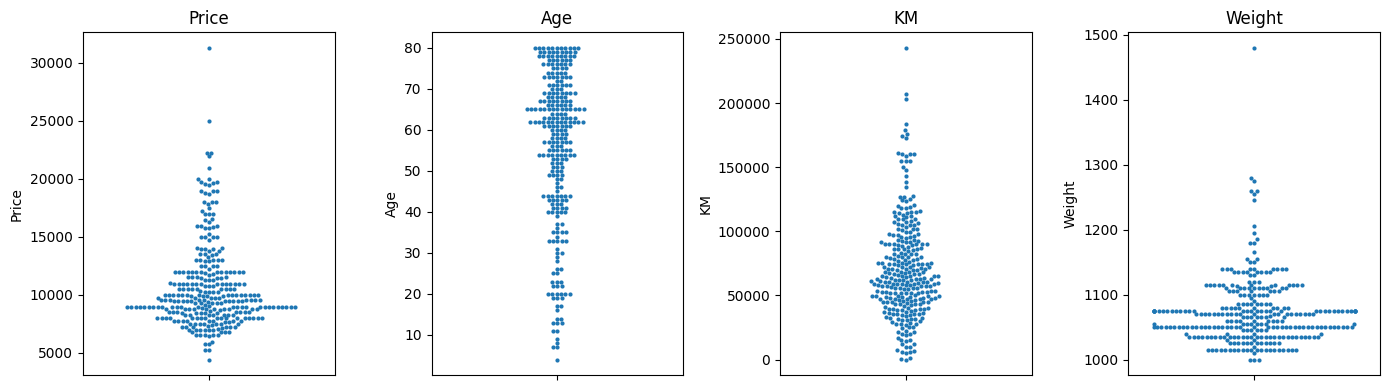

In [5]:
sample = df.sample(300, random_state=1)        # 1436 dots is too many for a swarm plot, so plot 300
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col in zip(axes, ["Price", "Age", "KM", "Weight"]):
    sns.swarmplot(y=sample[col], ax=ax, size=3)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Q1.5 Mode imputation for categorical data if missing > 10%

In [6]:
pct = df.isnull().mean() * 100                      # % missing in every column
for col in cat_cols:
    if pct[col] > 10:
        df[col] = df[col].fillna(df[col].mode()[0])
        print(f"{col}: {pct[col]:.1f}% missing -> filled with mode")
    else:
        print(f"{col}: {pct[col]:.1f}% missing -> not more than 10%, left as it is")

FuelType: 7.0% missing -> not more than 10%, left as it is
MetColor: 10.4% missing -> filled with mode
Automatic: 0.0% missing -> not more than 10%, left as it is


Only **MetColor** (10.4%) is above 10%, so only it is filled.

---
## Question 2

### Q2.1 Read and divide into training (75%) and testing (25%)

In [7]:
kasol = pd.read_csv("data/Kasol.csv").dropna()
X = kasol.drop(columns=["Unnamed: 0", "Discharge"])     # every column except the date and the target
y = kasol["Discharge"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (5468, 6)  Test: (1823, 6)


### Q2.2 Impact of multiple attributes: intercept and coefficients

In [8]:
from sklearn.linear_model import LinearRegression

model = LinearRegression().fit(X_train, y_train)
print("Intercept:", round(model.intercept_, 4))
print(pd.Series(model.coef_, index=X.columns).round(4))

Intercept: 110.3711
Tmin         48.8302
Rainfall      1.6231
RH          472.0102
Solar         8.2459
Wind        -52.6075
Tmax        -21.5213
dtype: float64


### Q2.3 Predict discharge for the test set

In [9]:
y_pred = model.predict(X_test)
pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred}).head()

,Actual,Predicted
0,128.40,49.290795
1,180.00,287.498917
2,84.20,90.012828
3,85.80,-66.524615
4,778.94,445.849585


### Q2.4 Display the regression line
With many X columns, plot **actual vs predicted**. A perfect model puts every dot on the red line.

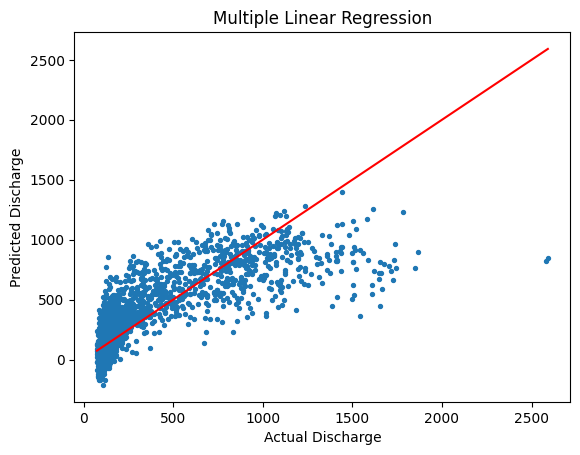

In [10]:
plt.scatter(y_test, y_pred, s=8)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Actual Discharge")
plt.ylabel("Predicted Discharge")
plt.title("Multiple Linear Regression")
plt.show()

### Q2.5 MSE and RMSE

In [11]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, y_pred)
print("MSE :", round(mse, 2))
print("RMSE:", round(np.sqrt(mse), 2))

MSE : 58601.06
RMSE: 242.08
